In [29]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data_dir = Path("data/optuna_regional_gee_configs")
artifact_dir = Path("data/feature_selection_artifacts")
# TARGET_REGION = "DES"
TARGET_REGION = "ICR"  # Change this to the desired region (e.g., 'DES', 'IGP', 'WGR', 'ICR', 'NEI', 'PEN', 'HIM')

trials_json_path = data_dir / f"{TARGET_REGION}_all_trials.json"
assert trials_json_path.exists(), f"File not found: {trials_json_path}"

with open(trials_json_path, "r") as f:
    trials_raw = json.load(f)

# Process the new flat Optuna JSON format into the expected DataFrame structure
processed_trials = []
for t in trials_raw:
    if t.get("state") != "COMPLETE":
        continue
    processed_trials.append({
        "trial_number": int(t["number"]),
        "macro_f1": float(t["values_0"]),
        "model_complexity": float(t["values_1"]),
        "samples_per_year": int(t.get("user_attrs_samples_per_year", 0)),
        "num_input_features": int(t.get("user_attrs_num_features", 0)),
        "numberOfTrees": int(t.get("params_numberOfTrees", 0)),
        "minLeafPopulation": int(t.get("params_minLeafPopulation", 0)),
        "train_fraction": float(t.get("params_train_fraction", 0.0)),
        "feature_strategy": str(t.get("params_feature_strategy", "")),
        "sampling_strategy": str(t.get("params_sampling_strategy", ""))
    })

df_all = pd.DataFrame(processed_trials)

# Dynamically compute the Pareto frontier (Maximize F1, Minimize Complexity)
is_pareto = []
for i, row in df_all.iterrows():
    f1 = row["macro_f1"]
    comp = row["model_complexity"]
    dominated = False
    for j, other in df_all.iterrows():
        if i == j: continue
        # A trial is dominated if another trial is equal or better on all axes, and strictly better on at least one
        if (other["macro_f1"] >= f1) and (other["model_complexity"] <= comp) and \
           ((other["macro_f1"] > f1) or (other["model_complexity"] < comp)):
            dominated = True
            break
    is_pareto.append(not dominated)
    
df_all["is_pareto"] = is_pareto
trials_by_number = {row["trial_number"]: row.to_dict() for _, row in df_all.iterrows()}

# Filter to Pareto-optimal trials and sort by complexity
df_pareto = df_all[df_all["is_pareto"]].sort_values("model_complexity").copy().reset_index(drop=True)

print(f"Loaded {len(df_all)} COMPLETE trials for Region '{TARGET_REGION}'.")
print(f"Found {len(df_pareto)} non-dominated Pareto frontier candidates.")

Loaded 40 COMPLETE trials for Region 'ICR'.
Found 9 non-dominated Pareto frontier candidates.


In [30]:
display_cols = [
    "trial_number", "macro_f1", "model_complexity", "samples_per_year",
    "num_input_features", "numberOfTrees", "minLeafPopulation",
    "train_fraction", "feature_strategy", "sampling_strategy"
]

print("=== Pareto Frontier Candidates ===")
with pd.option_context('display.max_columns', None, 'display.width', 1000):
    print(df_pareto[display_cols].to_string(index=False))

=== Pareto Frontier Candidates ===
 trial_number  macro_f1  model_complexity  samples_per_year  num_input_features  numberOfTrees  minLeafPopulation  train_fraction feature_strategy  sampling_strategy
           19  0.916374      3.631166e+09              7106                  20             50                  7             0.1              all         stratified
           11  0.922585      5.266434e+09              7106                  11            125                  7             0.1              all         stratified
           34  0.945171      1.371199e+10              7110                  39             50                  3             0.1     uncorrelated reference_balanced
           39  0.951281      2.526805e+10              7110                  39             75                  2             0.1     uncorrelated reference_balanced
           21  0.964790      3.172942e+10             19731                  26             50                  6             0.3      

In [31]:
# Baseline references
peak_f1 = df_pareto["macro_f1"].max()
min_comp = df_pareto["model_complexity"].min()
max_comp = df_pareto["model_complexity"].max()
min_f1 = df_pareto["macro_f1"].min()

# ----------------------------------------------------
# Strategy A: Epsilon-Tolerance (Within 1.0% of Peak F1)
# ----------------------------------------------------
F1_TOLERANCE = 0.010
viable_eps = df_pareto[df_pareto["macro_f1"] >= (peak_f1 - F1_TOLERANCE)]
trial_strat_a = int(viable_eps.loc[viable_eps["model_complexity"].idxmin()]["trial_number"])

# ----------------------------------------------------
# Strategy B: Normalized Utopia Distance
# ----------------------------------------------------
f1_penalty = (peak_f1 - df_pareto["macro_f1"]) / (peak_f1 - min_f1)
comp_penalty = (df_pareto["model_complexity"] - min_comp) / (max_comp - min_comp)

df_pareto["utopia_dist"] = np.sqrt(f1_penalty**2 + comp_penalty**2)
trial_strat_b = int(df_pareto.loc[df_pareto["utopia_dist"].idxmin()]["trial_number"])

# ----------------------------------------------------
# Strategy C: Marginal Return Ratio vs Baseline
# ----------------------------------------------------
log_comp = np.log10(df_pareto["model_complexity"])
log_base = np.log10(min_comp)
marginal_gain = (df_pareto["macro_f1"] - min_f1) / (log_comp - log_base).replace(0, np.nan)
df_pareto["marginal_return"] = marginal_gain.fillna(0.0)
trial_strat_c = int(df_pareto.loc[df_pareto["marginal_return"].idxmax()]["trial_number"])

# Comparison Table
selection_summary = []
for strat_name, t_num in [
    (f"Strategy A: Min Complexity (F1 drop <= {F1_TOLERANCE:.3f})", trial_strat_a),
    ("Strategy B: Normalized Utopia Distance", trial_strat_b),
    ("Strategy C: Max Marginal Return per Log-Complexity", trial_strat_c),
    ("Baseline: Absolute Peak F1 (Unconstrained)", int(df_pareto.loc[df_pareto["macro_f1"].idxmax()]["trial_number"]))
]:
    t_row = df_pareto[df_pareto["trial_number"] == t_num].iloc[0]
    selection_summary.append({
        "Strategy": strat_name,
        "Trial": int(t_num),
        "Macro-F1": t_row["macro_f1"],
        "F1 Delta vs Peak": t_row["macro_f1"] - peak_f1,
        "Complexity": t_row["model_complexity"],
        "Complexity Reduction vs Peak": f"{max_comp / t_row['model_complexity']:.1f}x smaller",
        "Trees": int(t_row["numberOfTrees"]),
        "MinLeaf": int(t_row["minLeafPopulation"]),
        "Features": int(t_row["num_input_features"]),
        "Samples": int(t_row["samples_per_year"])
    })

df_selection_summary = pd.DataFrame(selection_summary)
print("\n=== Multi-Criteria Selection Comparison ===")
with pd.option_context('display.max_columns', None, 'display.width', 1000):
    print(df_selection_summary.to_string(index=False))


=== Multi-Criteria Selection Comparison ===
                                          Strategy  Trial  Macro-F1  F1 Delta vs Peak   Complexity Complexity Reduction vs Peak  Trees  MinLeaf  Features  Samples
     Strategy A: Min Complexity (F1 drop <= 0.010)      1  0.978054         -0.002977 5.684612e+10                10.7x smaller     50        7        14    41539
            Strategy B: Normalized Utopia Distance      1  0.978054         -0.002977 5.684612e+10                10.7x smaller     50        7        14    41539
Strategy C: Max Marginal Return per Log-Complexity      1  0.978054         -0.002977 5.684612e+10                10.7x smaller     50        7        14    41539
        Baseline: Absolute Peak F1 (Unconstrained)     37  0.981031          0.000000 6.086829e+11                 1.0x smaller     75        2        39    49772


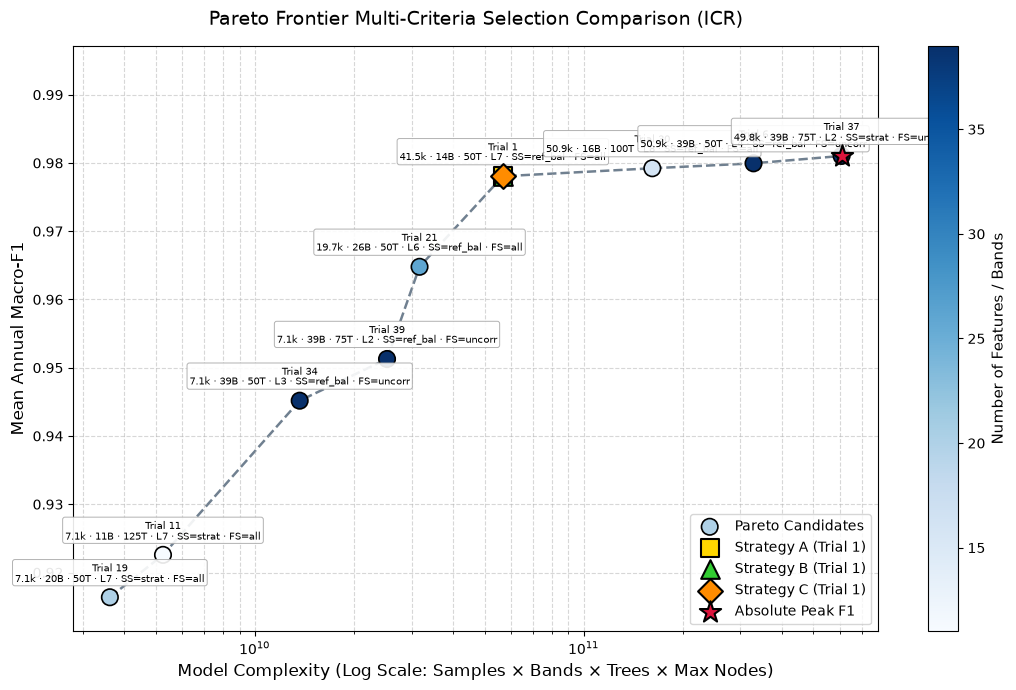

Selection visual saved -> data/optuna_regional_gee_configs/ICR_selection_comparison.png


In [32]:
# Cell 4: Visualizing the Strategies
plt.figure(figsize=(11, 7))

# 1. Draw Pareto line
plt.plot(df_pareto["model_complexity"], df_pareto["macro_f1"], color="slategray", linestyle="--", linewidth=1.8, zorder=1)

# 2. Scatter all Pareto candidates
scatter = plt.scatter(
    df_pareto["model_complexity"], df_pareto["macro_f1"], c=df_pareto["num_input_features"], 
    cmap="Blues", s=140, edgecolor="black", linewidth=1.2, zorder=2, label="Pareto Candidates"
)
cbar = plt.colorbar(scatter)
cbar.set_label("Number of Features / Bands", fontsize=11)

# 3. Mark selected strategy points
marker_styles = {
    f"Strategy A (Trial {trial_strat_a})": (trial_strat_a, "gold", "s", 180),
    f"Strategy B (Trial {trial_strat_b})": (trial_strat_b, "limegreen", "^", 180),
    f"Strategy C (Trial {trial_strat_c})": (trial_strat_c, "darkorange", "D", 160),
    f"Absolute Peak F1": (int(df_pareto.loc[df_pareto['macro_f1'].idxmax()]['trial_number']), "crimson", "*", 260)
}

for label, (t_num, color, marker, sz) in marker_styles.items():
    row = df_pareto[df_pareto["trial_number"] == t_num].iloc[0]
    plt.scatter(
        row["model_complexity"], row["macro_f1"], color=color, marker=marker, 
        s=sz, edgecolor="black", linewidth=1.5, zorder=4, label=label
    )

# 4. Annotate trial details (Updated to include samples_per_year)
# Strategy abbreviation mapping [Certain]
ss_abbr = {
    "stratified": "strat",
    "reference_balanced": "ref_bal"
}
fs_abbr = {
    "uncorrelated": "uncorr",
    "all": "all"
}

# 4. Annotate trial details with compact multi-line formatting
for _, row in df_pareto.iterrows():
    # Abbreviate strategies safely
    s_strat = ss_abbr.get(str(row["sampling_strategy"]).lower(), str(row["sampling_strategy"])[:4])
    f_strat = fs_abbr.get(str(row["feature_strategy"]).lower(), str(row["feature_strategy"])[:6])
    
    # 40,720 -> 40.7k, 4,519 -> 4.5k
    smp_k = f"{row['samples_per_year'] / 1000:.1f}k"

    label_text = (
        f"Trial {int(row['trial_number'])}\n"
        f"{smp_k} · {int(row['num_input_features'])}B · {int(row['numberOfTrees'])}T · "
        f"L{int(row['minLeafPopulation'])} · SS={s_strat} · FS={f_strat}"
    )

    plt.annotate(
        label_text,
        xy=(row["model_complexity"], row["macro_f1"]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=7,
        linespacing=1.1,
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="darkgray", lw=0.7, alpha=0.9)
    )

plt.xscale("log")
plt.title(f"Pareto Frontier Multi-Criteria Selection Comparison ({TARGET_REGION})", fontsize=14, pad=15)
plt.xlabel("Model Complexity (Log Scale: Samples × Bands × Trees × Max Nodes)", fontsize=12)
plt.ylabel("Mean Annual Macro-F1", fontsize=12)
plt.grid(True, which="both", linestyle="--", alpha=0.5)

y_pad = (peak_f1 - min_f1) * 0.25
plt.ylim(min_f1 - 0.005, peak_f1 + y_pad)
plt.legend(loc="lower right", frameon=True, fontsize=10)
plt.tight_layout()

comparison_plot_path = data_dir / f"{TARGET_REGION}_selection_comparison.png"
plt.savefig(comparison_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Selection visual saved -> {comparison_plot_path}")